In [1]:
import pandas as pd

In [3]:
df = pd.read_csv(r"C:\Users\mosha\Downloads\ADST\Car Sell Dataset (1).csv")

In [4]:
df.head()

,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
0,Mahindra,TUV300,AX5,SUV,Manual,CNG,2017,164654,1st,Rajasthan,No,547253
1,Skoda,Rapid,Style,Sedan,Manual,Petrol,2018,41351,1st,Maharashtra,No,512050
2,Maruti Suzuki,Alto,Z,Hatchback,Manual,Diesel,2002,119090,3rd+,Tamil Nadu,No,678923
3,Hyundai,Grand i10,Magna,Hatchback,Manual,Diesel,2013,19979,1st,Andhra Pradesh,No,522500
4,Mahindra,XUV500,W8,SUV,Manual,Petrol,2011,130591,3rd+,Bihar,No,401182


In [5]:
df.tail()

,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
140899,Mahindra,Scorpio,W11,SUV,Manual,Petrol,2002,62699,1st,Telangana,No,221067
140900,Hyundai,i10,Era,Hatchback,Manual,Petrol,2013,47953,2nd,Maharashtra,No,745360
140901,Honda,Jazz,V,Sedan,Automatic,Diesel,2009,134566,3rd+,Odisha,No,122852
140902,Honda,WR-V,E,SUV,Manual,Diesel,2022,88697,1st,Gujarat,No,502425
140903,Chevrolet,Tavera,Base,MPV,Manual,Diesel,2009,48117,2nd,Gujarat,No,905080


In [6]:
df.shape

(140904, 12)

In [7]:
df.columns

Index(['Brand', 'Model Name', 'Model Variant', 'Car Type', 'Transmission',
       'Fuel Type', 'Year', 'Kilometers', 'Owner', 'State', 'Accidental',
       'Price'],
      dtype='str')

In [8]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

Dataset Shape: (140904, 12)

Column Names:
['Brand', 'Model Name', 'Model Variant', 'Car Type', 'Transmission', 'Fuel Type', 'Year', 'Kilometers', 'Owner', 'State', 'Accidental', 'Price']

Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 140904 entries, 0 to 140903
Data columns (total 12 columns):
 #   Column         Non-Null Count   Dtype
---  ------         --------------   -----
 0   Brand          140904 non-null  str  
 1   Model Name     140904 non-null  str  
 2   Model Variant  140904 non-null  str  
 3   Car Type       140904 non-null  str  
 4   Transmission   140904 non-null  str  
 5   Fuel Type      140904 non-null  str  
 6   Year           140904 non-null  int64
 7   Kilometers     140904 non-null  int64
 8   Owner          140904 non-null  str  
 9   State          140904 non-null  str  
 10  Accidental     140904 non-null  str  
 11  Price          140904 non-null  int64
dtypes: int64(3), str(9)
memory usage: 19.5 MB


In [9]:
# Check missing values in each column

print(df.isnull().sum())

Brand            0
Model Name       0
Model Variant    0
Car Type         0
Transmission     0
Fuel Type        0
Year             0
Kilometers       0
Owner            0
State            0
Accidental       0
Price            0
dtype: int64


In [10]:
# Check duplicate rows

print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [11]:
# Numerical columns ka statistical summary

df.describe()


,Year,Kilometers,Price
count,140904.000000,140904.000000,1.409040e+05
mean,2016.960391,95024.595987,7.617872e+05
std,5.106106,49133.157878,4.438578e+05
min,2000.000000,10000.000000,5.005500e+04
25%,2014.000000,52421.000000,4.116420e+05
50%,2018.000000,94973.500000,6.828030e+05
75%,2021.000000,137618.000000,1.034178e+06
max,2023.000000,179998.000000,2.744280e+06


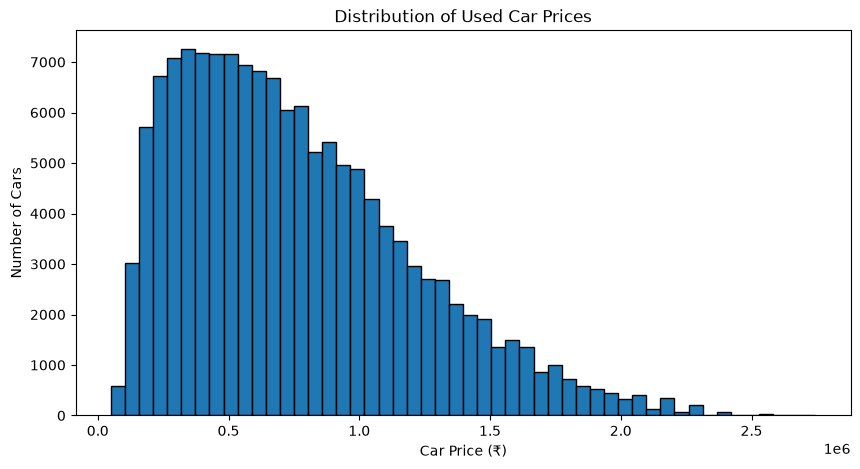

In [12]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.hist(df["Price"], bins=50, edgecolor="black")

plt.title("Distribution of Used Car Prices")
plt.xlabel("Car Price (₹)")
plt.ylabel("Number of Cars")

plt.show()

In [13]:
# 5 sabse sasti cars
print("Cheapest Cars:")
display(df.nsmallest(5, "Price"))

# 5 sabse mehengi cars
print("Most Expensive Cars:")
display(df.nlargest(5, "Price"))

Cheapest Cars:


,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
83446,Maruti Suzuki,Swift,L,Sedan,Manual,Petrol,2011,158345,3rd+,Punjab,Yes,50055
88946,Maruti Suzuki,Dzire,V,Sedan,Manual,Petrol,2009,138553,3rd+,Chandigarh,Yes,51611
64908,Toyota,Etios,V,Sedan,Manual,Diesel,2011,123783,3rd+,Uttar Pradesh,Yes,53201
65721,Honda,City,E,Sedan,Manual,Petrol,2014,107387,3rd+,Rajasthan,Yes,54885
51090,Hyundai,i10,SX,Hatchback,Manual,Petrol,2012,117639,3rd+,Rajasthan,Yes,56062


Most Expensive Cars:


,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
111342,Honda,WR-V,ZX,SUV,Automatic,Petrol,2022,45253,1st,Delhi,No,2744280
112731,Honda,WR-V,ZX,SUV,Manual,Electric,2020,19083,1st,Maharashtra,No,2744280
35082,BMW,X1,M Sport,Luxury,Automatic,Petrol,2023,35182,1st,Delhi,No,2662000
132046,Range Rover,Velar,SE,Luxury,Automatic,Petrol,2023,26808,1st,Maharashtra,No,2662000
137444,MG,ZS EV,Sharp,Luxury,Automatic,Diesel,2021,37059,1st,Tamil Nadu,No,2662000


In [14]:
# Har brand ke saath kaunse models hain, check karo

brand_model = (
    df.groupby(["Brand", "Model Name"])
    .size()
    .reset_index(name="Count")
)

display(brand_model.sort_values("Count", ascending=False))

,Brand,Model Name,Count
47,Maruti Suzuki,Dzire,6157
48,Maruti Suzuki,Ertiga,6037
52,Maruti Suzuki,WagonR,6022
51,Maruti Suzuki,Swift,6004
45,Maruti Suzuki,Baleno,6003
...,...,...,...
10,Chevrolet,Cruze,165
13,Chevrolet,Tavera,154
12,Chevrolet,Spark,153
11,Chevrolet,Sail,141


In [15]:
# Model aur fuel type combinations check karo

fuel_check = (
    df.groupby(["Brand", "Model Name", "Fuel Type"])
    .size()
    .reset_index(name="Count")
    .sort_values(["Brand", "Model Name"])
)

display(fuel_check)

,Brand,Model Name,Fuel Type,Count
0,Audi,A4,CNG,24
1,Audi,A4,Diesel,46
2,Audi,A4,Electric,3
3,Audi,A4,Hybrid,6
4,Audi,A4,Petrol,97
...,...,...,...,...
414,Volkswagen,Vento,CNG,80
415,Volkswagen,Vento,Diesel,286
416,Volkswagen,Vento,Electric,20
417,Volkswagen,Vento,Hybrid,20


In [16]:
# Selected suspicious fuel combinations ko inspect karna

check_models = [
    ("Audi", "A4"),
    ("Volkswagen", "Vento"),
    ("Honda", "WR-V"),
    ("MG", "ZS EV")
]

for brand_name, model_name in check_models:

    print(f"\n{brand_name} - {model_name}")

    records = df[
        (df["Brand"] == brand_name) &
        (df["Model Name"] == model_name)
    ]

    display(
        records[
            ["Brand", "Model Name", "Model Variant",
             "Year", "Fuel Type", "Transmission", "Price"]
        ].sort_values("Fuel Type")
    )


Audi - A4


,Brand,Model Name,Model Variant,Year,Fuel Type,Transmission,Price
6417,Audi,A4,Premium Plus,2009,CNG,Manual,424400
6939,Audi,A4,Premium,2009,CNG,Manual,655215
9139,Audi,A4,Premium Plus,2009,CNG,Automatic,555976
11095,Audi,A4,Premium Plus,2014,CNG,Manual,184279
11356,Audi,A4,Technology,2019,CNG,Manual,405109
...,...,...,...,...,...,...,...
135136,Audi,A4,Premium,2021,Petrol,Manual,206910
135265,Audi,A4,Premium Plus,2009,Petrol,Manual,900058
135919,Audi,A4,Premium Plus,2015,Petrol,Manual,502573
137045,Audi,A4,Premium Plus,2019,Petrol,Manual,659547



Volkswagen - Vento


,Brand,Model Name,Model Variant,Year,Fuel Type,Transmission,Price
1162,Volkswagen,Vento,GT,2012,CNG,Automatic,264270
4177,Volkswagen,Vento,Trendline,2010,CNG,Manual,480491
5564,Volkswagen,Vento,Comfortline,2012,CNG,Automatic,183931
7274,Volkswagen,Vento,Highline+,2018,CNG,Manual,1010865
11009,Volkswagen,Vento,Comfortline,2010,CNG,Manual,427527
...,...,...,...,...,...,...,...
138622,Volkswagen,Vento,Highline+,2022,Petrol,Manual,940500
139908,Volkswagen,Vento,Highline,2020,Petrol,Manual,1018875
140025,Volkswagen,Vento,Highline,2022,Petrol,Manual,1636470
140359,Volkswagen,Vento,Highline,2021,Petrol,Manual,295077



Honda - WR-V


,Brand,Model Name,Model Variant,Year,Fuel Type,Transmission,Price
74,Honda,WR-V,ZX,2020,CNG,Manual,824780
305,Honda,WR-V,S,2020,CNG,Manual,1008065
1076,Honda,WR-V,E,2022,CNG,Manual,1909215
2639,Honda,WR-V,S,2020,CNG,Manual,1145529
3094,Honda,WR-V,ZX,2018,CNG,Manual,492735
...,...,...,...,...,...,...,...
140274,Honda,WR-V,V,2017,Petrol,Manual,374206
140678,Honda,WR-V,E,2018,Petrol,Manual,646222
140801,Honda,WR-V,ZX,2021,Petrol,Manual,748440
140807,Honda,WR-V,V,2021,Petrol,Manual,463068



MG - ZS EV


,Brand,Model Name,Model Variant,Year,Fuel Type,Transmission,Price
911,MG,ZS EV,Style,2021,CNG,Manual,1494350
2951,MG,ZS EV,Savvy,2020,CNG,Manual,689700
4127,MG,ZS EV,Super,2023,CNG,Manual,459800
4468,MG,ZS EV,Smart,2023,CNG,Manual,1264450
9047,MG,ZS EV,Sharp,2021,CNG,Manual,1379400
...,...,...,...,...,...,...,...
137465,MG,ZS EV,Super,2022,Petrol,Automatic,1505361
138233,MG,ZS EV,Super,2021,Petrol,Manual,1542750
138810,MG,ZS EV,Super,2021,Petrol,Manual,998250
138832,MG,ZS EV,Smart,2020,Petrol,Manual,638880


In [17]:
# Selected models mein fuel type ka distribution

check_models = [
    ("Audi", "A4"),
    ("Volkswagen", "Vento"),
    ("Honda", "WR-V"),
    ("MG", "ZS EV")
]

for brand_name, model_name in check_models:

    records = df[
        (df["Brand"] == brand_name) &
        (df["Model Name"] == model_name)
    ]

    print(f"\n{brand_name} {model_name}")
    print(records["Fuel Type"].value_counts())


Audi A4
Fuel Type
Petrol      97
Diesel      46
CNG         24
Hybrid       6
Electric     3
Name: count, dtype: int64

Volkswagen Vento
Fuel Type
Petrol      522
Diesel      286
CNG          80
Hybrid       20
Electric     20
Name: count, dtype: int64

Honda WR-V
Fuel Type
Petrol      1320
Diesel       726
CNG          232
Hybrid        58
Electric      54
Name: count, dtype: int64

MG ZS EV
Fuel Type
Petrol      267
Diesel      151
CNG          41
Electric      9
Hybrid        8
Name: count, dtype: int64


In [18]:
# Fuel type aur car type ka distribution

fuel_car_type = pd.crosstab(
    df["Car Type"],
    df["Fuel Type"]
)

display(fuel_car_type)

Fuel Type,CNG,Diesel,Electric,Hybrid,Petrol
Car Type,,,,,
Hatchback,5574,16616,1108,1106,31486
Luxury,338,1027,70,51,1872
MPV,960,2861,188,192,5501
SUV,3532,10549,714,699,19563
Sedan,3650,10985,773,724,20765


In [19]:
# Overall fuel type distribution

print(df["Fuel Type"].value_counts())

print("\nFuel type percentage:")
print(
    (df["Fuel Type"].value_counts(normalize=True) * 100)
    .round(2)
)

Fuel Type
Petrol      79187
Diesel      42038
CNG         14054
Electric     2853
Hybrid       2772
Name: count, dtype: int64

Fuel type percentage:
Fuel Type
Petrol      56.20
Diesel      29.83
CNG          9.97
Electric     2.02
Hybrid       1.97
Name: proportion, dtype: float64


In [20]:
# Brand, model aur fuel type ke combinations

fuel_by_model = (
    df.groupby(["Brand", "Model Name", "Fuel Type"])
      .size()
      .reset_index(name="Count")
)

# Har model ke liye fuel types aur counts
display(
    fuel_by_model.sort_values(
        ["Brand", "Model Name", "Count"],
        ascending=[True, True, False]
    )
)

,Brand,Model Name,Fuel Type,Count
4,Audi,A4,Petrol,97
1,Audi,A4,Diesel,46
0,Audi,A4,CNG,24
3,Audi,A4,Hybrid,6
2,Audi,A4,Electric,3
...,...,...,...,...
418,Volkswagen,Vento,Petrol,522
415,Volkswagen,Vento,Diesel,286
414,Volkswagen,Vento,CNG,80
416,Volkswagen,Vento,Electric,20


In [21]:
# Electric fuel wali cars ke brand-model combinations

electric_cars = (
    df[df["Fuel Type"] == "Electric"]
    .groupby(["Brand", "Model Name"])
    .size()
    .reset_index(name="Count")
    .sort_values("Count", ascending=False)
)

display(electric_cars)

,Brand,Model Name,Count
51,Maruti Suzuki,Swift,129
49,Maruti Suzuki,Ignis,128
47,Maruti Suzuki,Dzire,126
46,Maruti Suzuki,Celerio,122
44,Maruti Suzuki,Alto,121
...,...,...,...
12,Chevrolet,Spark,3
58,Range Rover,Evoque,3
10,Chevrolet,Cruze,2
11,Chevrolet,Sail,2


In [22]:
fuel_check = (
    df.groupby(["Brand", "Model Name"])["Fuel Type"]
    .agg(lambda x: sorted(x.unique()))
    .reset_index(name="Fuel Types")
)

display(fuel_check)

,Brand,Model Name,Fuel Types
0,Audi,A4,"[CNG, Diesel, Electric, Hybrid, Petrol]"
1,Audi,A6,"[CNG, Diesel, Electric, Hybrid, Petrol]"
2,Audi,Q3,"[CNG, Diesel, Electric, Hybrid, Petrol]"
3,Audi,Q5,"[CNG, Diesel, Electric, Hybrid, Petrol]"
4,Audi,Q7,"[CNG, Diesel, Electric, Hybrid, Petrol]"
...,...,...,...
79,Toyota,Urban Cruiser,"[CNG, Diesel, Electric, Hybrid, Petrol]"
80,Volkswagen,Ameo,"[CNG, Diesel, Electric, Hybrid, Petrol]"
81,Volkswagen,Polo,"[CNG, Diesel, Electric, Hybrid, Petrol]"
82,Volkswagen,Taigun,"[CNG, Diesel, Electric, Hybrid, Petrol]"


In [23]:
# Har brand-model combination mein fuel types ka percentage

fuel_distribution = pd.crosstab(
    [df["Brand"], df["Model Name"]],
    df["Fuel Type"],
    normalize="index"
).round(3)

display(fuel_distribution.head(15))

Fuel Type               CNG  Diesel  Electric  Hybrid  Petrol
Brand     Model Name                                         
Audi      A4          0.136   0.261     0.017   0.034   0.551
          A6          0.064   0.351     0.025   0.005   0.554
          Q3          0.101   0.275     0.024   0.005   0.594
          Q5          0.119   0.317     0.020   0.015   0.530
          Q7          0.089   0.324     0.018   0.027   0.542
BMW       3 Series    0.089   0.300     0.019   0.012   0.580
          5 Series    0.111   0.309     0.024   0.017   0.538
          X1          0.110   0.289     0.022   0.033   0.546
          X3          0.111   0.278     0.021   0.013   0.577
Chevrolet Beat        0.072   0.331     0.014   0.029   0.554
          Cruze       0.127   0.285     0.012   0.000   0.576
          Sail        0.099   0.262     0.014   0.021   0.603
          Spark       0.131   0.216     0.020   0.033   0.601
          Tavera      0.097   0.266     0.039   0.006   0.591
Ford      Aspire      0.113   0.280     0.018   0.021   0.568

In [24]:
# Same brand, model aur year ke liye price statistics

price_check = (
    df.groupby(["Brand", "Model Name", "Year"])["Price"]
    .agg(["count", "mean", "median", "min", "max"])
    .reset_index()
)

display(
    price_check.sort_values(
        "count",
        ascending=False
    ).head(20)
)

,Brand,Model Name,Year,count,mean,median,min,max
575,Maruti Suzuki,S-Presso,2019,1225,6.971934e+05,672043.0,88061,1689765
579,Maruti Suzuki,S-Presso,2023,1188,1.031634e+06,1011076.0,121806,2613600
578,Maruti Suzuki,S-Presso,2022,1174,9.929612e+05,950400.0,148570,2420000
576,Maruti Suzuki,S-Presso,2020,1169,1.011790e+06,989019.0,135775,2482920
577,Maruti Suzuki,S-Presso,2021,1146,9.908407e+05,950400.0,146703,2482920
569,Maruti Suzuki,Ignis,2018,892,7.105637e+05,693346.5,95112,1609977
571,Maruti Suzuki,Ignis,2020,879,1.007320e+06,974700.0,148985,2376000
574,Maruti Suzuki,Ignis,2023,867,1.014745e+06,990000.0,167098,2420000
573,Maruti Suzuki,Ignis,2022,866,1.007777e+06,972562.0,150083,2515590
572,Maruti Suzuki,Ignis,2021,825,9.743918e+05,943800.0,130635,2613600


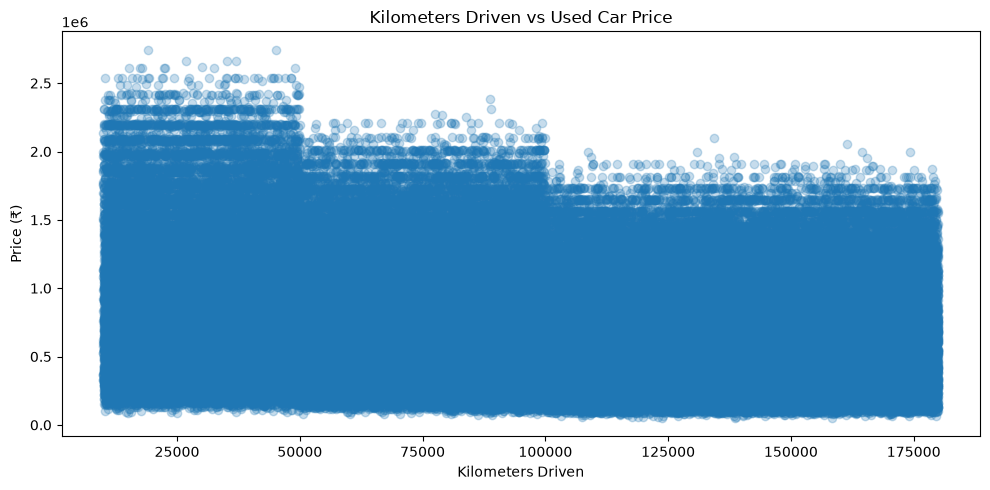

In [25]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.scatter(
    df["Kilometers"],
    df["Price"],
    alpha=0.25
)

plt.title("Kilometers Driven vs Used Car Price")
plt.xlabel("Kilometers Driven")
plt.ylabel("Price (₹)")

plt.tight_layout()
plt.show()

In [26]:
df[["Kilometers", "Price"]].corr()

,Kilometers,Price
Kilometers,1.000000,-0.214301
Price,-0.214301,1.000000


In [27]:
print("Total rows:", len(df))
print("Unique prices:", df["Price"].nunique())
print("Most repeated prices:")
print(df["Price"].value_counts().head(10))

Total rows: 140904
Unique prices: 17745
Most repeated prices:
Price
693000     433
346500     409
1039500    399
1097250    398
1155000    395
1386000    329
762300     329
577500     323
1016400    308
1212750    305
Name: count, dtype: int64


In [28]:
print("Price multiples check:")
print((df["Price"] % 1000).value_counts().head(10))

print("\nPrice distribution:")
print(df["Price"].quantile([0, 0.25, 0.50, 0.75, 0.90, 0.99, 1]))

Price multiples check:
Price
0      10377
500     6181
250     2443
750     2221
800     1922
600     1706
400     1661
200     1652
300     1042
375     1032
Name: count, dtype: int64

Price distribution:
0.00      50055.00
0.25     411642.00
0.50     682803.00
0.75    1034178.25
0.90    1389850.00
0.99    2009700.00
1.00    2744280.00
Name: Price, dtype: float64


In [29]:
check_cols = [
    "Brand", "Model Name", "Model Variant",
    "Year", "Kilometers"
]

price_check = (
    df.groupby(check_cols)["Price"]
    .agg(["count", "min", "max", "median"])
    .reset_index()
)

price_check["price_difference"] = (
    price_check["max"] - price_check["min"]
)

print(
    price_check[price_check["count"] >= 5]
    .sort_values("price_difference", ascending=False)
    .head(10)
)

Empty DataFrame
Columns: [Brand, Model Name, Model Variant, Year, Kilometers, count, min, max, median, price_difference]
Index: []


In [31]:
print("Total matching groups:", (price_check["count"] >= 2).sum())

print(
    price_check[price_check["count"] >= 2]
    .sort_values("price_difference", ascending=False)
    .head(10)
    .to_string(index=False)
)

Total matching groups: 18
        Brand Model Name Model Variant  Year  Kilometers  count    min     max    median  price_difference
Maruti Suzuki      Ignis             V  2017       42690      2 308000 1386000  847000.0           1078000
      Hyundai       Aura         SX(O)  2020       61972      2 471105 1292083  881594.0            820978
      Hyundai      Creta        Sportz  2017       22640      2 418950 1212750  815850.0            793800
Maruti Suzuki   S-Presso             L  2023       70985      2 734976 1309176 1022076.0            574200
Maruti Suzuki    Celerio             L  2022      120555      2 609840 1132560  871200.0            522720
Maruti Suzuki      Swift             L  2021      111291      2 194940  526680  360810.0            331740
      Hyundai  Grand i10         SX(O)  2015      123232      2 808500 1118040  963270.0            309540
Maruti Suzuki    Celerio             Z  2016       72622      2 914413 1195771 1055092.0            281358
Maruti Suzu

In [32]:
cols = [
    "Brand", "Model Name", "Model Variant", "Car Type",
    "Transmission", "Fuel Type", "Year", "Kilometers",
    "Owner", "State", "Accidental", "Price"
]

print(
    df[
        (df["Brand"] == "Maruti Suzuki") &
        (df["Model Name"] == "Ignis") &
        (df["Model Variant"] == "V") &
        (df["Year"] == 2017) &
        (df["Kilometers"] == 42690)
    ][cols].to_string(index=False)
)

        Brand Model Name Model Variant  Car Type Transmission Fuel Type  Year  Kilometers Owner       State Accidental   Price
Maruti Suzuki      Ignis             V Hatchback       Manual    Petrol  2017       42690   1st Maharashtra         No 1386000
Maruti Suzuki      Ignis             V Hatchback       Manual    Petrol  2017       42690   1st     Gujarat         No  308000


In [33]:
state_check = (
    df.groupby("State")["Price"]
    .agg(["count", "mean", "median", "min", "max"])
    .round(0)
)

print(state_check)

                  count      mean    median     min      max
State                                                       
Andhra Pradesh     2767  679887.0  615956.0   60785  2194500
Assam               686  693248.0  627186.0   73879  2184050
Bihar              1363  672206.0  588038.0   90560  1995000
Chandigarh          640  690655.0  598500.0   51611  2084775
Chhattisgarh        718  691790.0  629430.0   83763  2413950
Delhi             21518  783455.0  701153.0   62287  2744280
Goa                 715  680277.0  610948.0   71813  1900000
Gujarat           12389  787397.0  704045.0   63623  2482920
Haryana            1365  698287.0  620730.0   83763  1995000
Himachal Pradesh    399  706805.0  640041.0  106144  2084775
Jammu & Kashmir     400  670422.0  584106.0   83763  2052000
Jharkhand           716  686385.0  610068.0   88171  1995000
Karnataka         18981  787278.0  704365.0   67626  2619540
Kerala             5434  683157.0  614460.0   71131  2194500
Madhya Pradesh     2674 

In [34]:
year_check = (
    df.groupby("Year")["Price"]
    .agg(["count", "mean", "median"])
    .round(0)
)

print(year_check.to_string())

      count       mean    median
Year                            
2000    732   532650.0  511040.0
2001    720   518309.0  493448.0
2002    804   515577.0  479160.0
2003    836   515958.0  493448.0
2004    866   502480.0  461191.0
2005   1319   501113.0  476437.0
2006   1453   497934.0  471673.0
2007   1504   489497.0  459814.0
2008   2469   491881.0  473715.0
2009   2964   492860.0  459800.0
2010   3606   490098.0  464526.0
2011   4264   496243.0  467277.0
2012   5050   499261.0  470720.0
2013   5708   497877.0  469724.0
2014   5706   495116.0  475238.0
2015   7363   690922.0  667012.0
2016   7797   683630.0  658350.0
2017   9687   689401.0  667012.0
2018   9479   690519.0  667012.0
2019  12367   695950.0  672043.0
2020  14608   993825.0  952875.0
2021  14314  1001881.0  965580.0
2022  14283  1000299.0  970200.0
2023  13005  1002173.0  972694.0


In [35]:
print(pd.crosstab(df["Year"], df["Car Type"], normalize="index").round(2))

print("\nBrand count by year:")
print(pd.crosstab(df["Year"], df["Brand"]).iloc[:, :10])

Car Type  Hatchback  Luxury   MPV   SUV  Sedan
Year                                          
2000           0.71    0.03  0.00  0.12   0.14
2001           0.69    0.03  0.00  0.12   0.16
2002           0.64    0.03  0.00  0.20   0.13
2003           0.57    0.02  0.00  0.27   0.14
2004           0.56    0.02  0.01  0.27   0.14
2005           0.40    0.01  0.08  0.18   0.33
2006           0.31    0.01  0.09  0.16   0.43
2007           0.36    0.01  0.08  0.15   0.40
2008           0.43    0.01  0.05  0.09   0.42
2009           0.42    0.01  0.05  0.13   0.40
2010           0.37    0.01  0.03  0.14   0.45
2011           0.38    0.01  0.03  0.17   0.41
2012           0.35    0.03  0.13  0.15   0.34
2013           0.34    0.02  0.12  0.16   0.35
2014           0.36    0.03  0.11  0.17   0.32
2015           0.37    0.02  0.08  0.22   0.30
2016           0.38    0.03  0.08  0.21   0.31
2017           0.40    0.02  0.06  0.25   0.26
2018           0.40    0.03  0.06  0.24   0.26
2019         

In [36]:
print("Total unique brands:", df["Brand"].nunique())
print("Total unique models:", df["Model Name"].nunique())

print("\nModels per brand:")
print(
    df.groupby("Brand")["Model Name"]
    .nunique()
    .sort_values(ascending=False)
    .to_string()
)

Total unique brands: 18
Total unique models: 84

Models per brand:
Brand
Maruti Suzuki    9
Hyundai          7
Skoda            5
Audi             5
Honda            5
Chevrolet        5
Toyota           5
Tata             5
Mahindra         5
BMW              4
Renault          4
Range Rover      4
Nissan           4
Ford             4
Volkswagen       4
MG               3
Jaguar           3
Kia              3


In [37]:
brand_model_check = (
    df.groupby(["Brand", "Model Name"])
    .size()
    .reset_index(name="Count")
)

print(brand_model_check.to_string(index=False))

        Brand      Model Name  Count
         Audi              A4    176
         Audi              A6    202
         Audi              Q3    207
         Audi              Q5    202
         Audi              Q7    225
          BMW        3 Series    257
          BMW        5 Series    288
          BMW              X1    273
          BMW              X3    234
    Chevrolet            Beat    139
    Chevrolet           Cruze    165
    Chevrolet            Sail    141
    Chevrolet           Spark    153
    Chevrolet          Tavera    154
         Ford          Aspire   1314
         Ford        EcoSport   1298
         Ford       Endeavour   1307
         Ford            Figo   1298
        Honda           Amaze   2353
        Honda            Brio   2368
        Honda            City   2404
        Honda            Jazz   2421
        Honda            WR-V   2390
      Hyundai            Aura   3103
      Hyundai           Creta   3188
      Hyundai       Grand i10   3238
 

In [38]:
fuel_check = (
    df.groupby(["Brand", "Model Name", "Fuel Type"])
    .size()
    .reset_index(name="Count")
)

for model in ["WR-V", "ZS EV", "Seltos", "Swift"]:
    print(f"\n--- {model} ---")
    print(
        fuel_check[fuel_check["Model Name"] == model]
        .to_string(index=False)
    )


--- WR-V ---
Brand Model Name Fuel Type  Count
Honda       WR-V       CNG    232
Honda       WR-V    Diesel    726
Honda       WR-V  Electric     54
Honda       WR-V    Hybrid     58
Honda       WR-V    Petrol   1320

--- ZS EV ---
Brand Model Name Fuel Type  Count
   MG      ZS EV       CNG     41
   MG      ZS EV    Diesel    151
   MG      ZS EV  Electric      9
   MG      ZS EV    Hybrid      8
   MG      ZS EV    Petrol    267

--- Seltos ---
Brand Model Name Fuel Type  Count
  Kia     Seltos       CNG     90
  Kia     Seltos    Diesel    197
  Kia     Seltos  Electric     15
  Kia     Seltos    Hybrid     11
  Kia     Seltos    Petrol    426

--- Swift ---
        Brand Model Name Fuel Type  Count
Maruti Suzuki      Swift       CNG    582
Maruti Suzuki      Swift    Diesel   1766
Maruti Suzuki      Swift  Electric    129
Maruti Suzuki      Swift    Hybrid    111
Maruti Suzuki      Swift    Petrol   3416


In [39]:
df.sample(10, random_state=42)

,Brand,Model Name,Model Variant,Car Type,Transmission,Fuel Type,Year,Kilometers,Owner,State,Accidental,Price
78981,Maruti Suzuki,Alto,L,Hatchback,Manual,Petrol,2021,170131,1st,Punjab,No,889200
78446,Honda,Jazz,S,Sedan,Manual,Petrol,2012,76631,2nd,Punjab,No,114007
131010,Maruti Suzuki,Alto,V,Hatchback,Manual,Petrol,2009,14983,2nd,Maharashtra,No,745360
80826,Mahindra,Scorpio,W10,SUV,Manual,Petrol,2009,54336,2nd,Gujarat,No,389077
136300,Honda,WR-V,VX,SUV,Automatic,Petrol,2019,102016,2nd,Karnataka,No,645668
112275,Maruti Suzuki,Swift,ZX,Sedan,Manual,Petrol,2006,107527,3rd+,Maharashtra,No,698321
31173,BMW,X1,M Sport,Luxury,Manual,Petrol,2015,40568,2nd,Maharashtra,No,1192576
14370,Honda,Amaze,S,Sedan,Automatic,Diesel,2017,14561,1st,Maharashtra,No,482790
39173,MG,ZS EV,Sharp,Luxury,Automatic,Petrol,2023,13981,1st,Tamil Nadu,No,2262700
96146,Honda,Brio,V,Hatchback,Manual,Petrol,2019,143978,2nd,Tamil Nadu,No,355740


In [40]:
df[df["Model Name"] == "ZS EV"][
    ["Brand", "Model Name", "Year", "Fuel Type", "Transmission", "Price"]
].sample(10, random_state=42)

,Brand,Model Name,Year,Fuel Type,Transmission,Price
137702,MG,ZS EV,2020,Diesel,Manual,958320
9047,MG,ZS EV,2021,CNG,Manual,1379400
39173,MG,ZS EV,2023,Petrol,Automatic,2262700
19741,MG,ZS EV,2020,Diesel,Automatic,1497375
21993,MG,ZS EV,2021,Petrol,Manual,1567500
33137,MG,ZS EV,2020,Petrol,Manual,369484
82679,MG,ZS EV,2021,Petrol,Manual,1310430
57326,MG,ZS EV,2021,CNG,Manual,1289739
80439,MG,ZS EV,2021,Petrol,Manual,363000
2848,MG,ZS EV,2020,Electric,Manual,305704


In [41]:
mg = df[df["Model Name"] == "ZS EV"]

print("Total records:", len(mg))
print("\nFuel type distribution:")
print(mg["Fuel Type"].value_counts())

print("\nTransmission distribution:")
print(mg["Transmission"].value_counts())

print("\nPrice summary:")
print(mg["Price"].describe())

Total records: 476

Fuel type distribution:
Fuel Type
Petrol      267
Diesel      151
CNG          41
Electric      9
Hybrid        8
Name: count, dtype: int64

Transmission distribution:
Transmission
Manual       397
Automatic     79
Name: count, dtype: int64

Price summary:
count    4.760000e+02
mean     1.096886e+06
std      5.389719e+05
min      2.069100e+05
25%      6.316200e+05
50%      1.043586e+06
75%      1.489125e+06
max      2.662000e+06
Name: Price, dtype: float64


In [42]:
fuel_summary = (
    df.groupby(["Brand", "Model Name", "Fuel Type"])
    .size()
    .reset_index(name="Count")
)

print("Total brand-model-fuel combinations:", len(fuel_summary))
print("\nNumber of models having all 5 fuel types:")
fuel_counts = df.groupby("Model Name")["Fuel Type"].nunique()
print((fuel_counts == 5).sum())

print("\nModels with all 5 fuel types:")
print(fuel_counts[fuel_counts == 5].index.tolist())


Total brand-model-fuel combinations: 419

Number of models having all 5 fuel types:
83

Models with all 5 fuel types:
['3 Series', '5 Series', 'A4', 'A6', 'Alto', 'Altroz', 'Amaze', 'Ameo', 'Aspire', 'Astor', 'Aura', 'Baleno', 'Beat', 'Bolero', 'Brio', 'Carens', 'Celerio', 'City', 'Creta', 'Discovery Sport', 'Duster', 'Dzire', 'EcoSport', 'Endeavour', 'Ertiga', 'Etios', 'Evoque', 'F-Pace', 'Figo', 'Fortuner', 'Glanza', 'Grand i10', 'Harrier', 'Hector', 'Ignis', 'Innova', 'Jazz', 'Kiger', 'Kushaq', 'Kwid', 'Magnite', 'Micra', 'Nexon', 'Octavia', 'Polo', 'Q3', 'Q5', 'Q7', 'Rapid', 'S-Presso', 'Sail', 'Scorpio', 'Seltos', 'Slavia', 'Sonet', 'Spark', 'Sport', 'Sunny', 'Superb', 'Swift', 'TUV300', 'Taigun', 'Tavera', 'Terrano', 'Thar', 'Tiago', 'Tigor', 'Triber', 'Urban Cruiser', 'Velar', 'Vento', 'Venue', 'Verna', 'WR-V', 'WagonR', 'X1', 'X3', 'XE', 'XF', 'XUV500', 'ZS EV', 'i10', 'i20']


In [43]:
print("Fuel types:", sorted(df["Fuel Type"].unique()))
print("\nTransmission types:", sorted(df["Transmission"].unique()))
print("\nOwner types:", sorted(df["Owner"].unique()))
print("\nCar types:", sorted(df["Car Type"].unique()))

Fuel types: ['CNG', 'Diesel', 'Electric', 'Hybrid', 'Petrol']

Transmission types: ['Automatic', 'Manual']

Owner types: ['1st', '2nd', '3rd+']

Car types: ['Hatchback', 'Luxury', 'MPV', 'SUV', 'Sedan']


In [44]:
model_year_check = (
    df.groupby(["Brand", "Model Name"])["Year"]
    .agg(["min", "max", "nunique"])
    .reset_index()
)

print(model_year_check.sort_values("min").head(20).to_string(index=False))

        Brand Model Name  min  max  nunique
          BMW   5 Series 2000 2023       24
          BMW   3 Series 2000 2023       24
        Honda       City 2000 2023       24
     Mahindra     Bolero 2000 2023       24
Maruti Suzuki       Alto 2000 2023       24
Maruti Suzuki     WagonR 2000 2023       24
        Skoda    Octavia 2001 2023       23
     Mahindra    Scorpio 2002 2023       22
         Ford  Endeavour 2003 2021       19
    Chevrolet     Tavera 2004 2017       14
        Skoda     Superb 2004 2023       20
Maruti Suzuki      Swift 2005 2023       19
       Toyota     Innova 2005 2023       19
      Hyundai      Verna 2006 2023       18
    Chevrolet      Spark 2007 2017       11
      Hyundai        i10 2008 2013        6
Maruti Suzuki      Dzire 2008 2023       16
         Audi         A4 2008 2023       16
      Hyundai        i20 2009 2023       15
    Chevrolet      Cruze 2009 2017        9


In [45]:
year_price = (
    df.groupby("Year")["Price"]
    .agg(["count", "min", "median", "max"])
    .round(0)
)

print(year_price.to_string())

      count     min    median      max
Year                                  
2000    732   63623  511040.0  1437480
2001    720   71577  493448.0  1437480
2002    804   79575  479160.0  1397550
2003    836   75947  493448.0  1331000
2004    866   71813  461191.0  1270500
2005   1319   82065  476437.0  1365606
2006   1453   86766  471673.0  1397550
2007   1504   68368  459814.0  1264450
2008   2469   58978  473715.0  1270500
2009   2964   51611  459800.0  1397550
2010   3606   62287  464526.0  1372140
2011   4264   50055  467277.0  1397550
2012   5050   56062  470720.0  1437480
2013   5708   58553  469724.0  1437480
2014   5706   54885  475238.0  1397550
2015   7363   94107  667012.0  1778700
2016   7797   90560  658350.0  1778700
2017   9687   79152  667012.0  1829520
2018   9479   87533  667012.0  1778700
2019  12367   88061  672043.0  1920996
2020  14608  122159  952875.0  2744280
2021  14314  126633  965580.0  2662000
2022  14283  134337  970200.0  2744280
2023  13005  117206  9726

In [46]:
print(
    df.groupby(["Brand", "Model Name", "Year"])["Price"]
    .agg(["count", "mean", "median", "std"])
    .sort_values("count", ascending=False)
    .head(10)
    .round(2)
)

                               count        mean     median        std
Brand         Model Name Year                                         
Maruti Suzuki S-Presso   2019   1225   697193.37   672043.0  336739.88
                         2023   1188  1031634.34  1011076.0  497918.21
                         2022   1174   992961.17   950400.0  501683.63
                         2020   1169  1011790.04   989019.0  514440.99
                         2021   1146   990840.67   950400.0  506762.34
              Ignis      2018    892   710563.65   693346.5  338015.88
                         2020    879  1007319.74   974700.0  494190.45
                         2023    867  1014745.40   990000.0  492164.25
                         2022    866  1007777.41   972562.0  495175.46
                         2021    825   974391.82   943800.0  486299.41


In [47]:
# Dataset validation summary

print("Dataset shape:", df.shape)

print("\nMissing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

print("\nUnique brands:", df["Brand"].nunique())
print("Unique models:", df["Model Name"].nunique())

print("\nInvalid year rows:")
print(len(df[(df["Year"] < 2000) | (df["Year"] > 2023)]))

print("\nInvalid kilometer rows:")
print(len(df[(df["Kilometers"] <= 0)]))

print("\nInvalid price rows:")
print(len(df[(df["Price"] <= 0)]))

Dataset shape: (140904, 12)

Missing values: 0
Duplicate rows: 0

Unique brands: 18
Unique models: 84

Invalid year rows:
0

Invalid kilometer rows:
0

Invalid price rows:
0


In [48]:
# Check categorical columns and their unique values

categorical_cols = [
    "Brand", "Model Name", "Model Variant",
    "Car Type", "Transmission", "Fuel Type",
    "Owner", "State", "Accidental"
]

for col in categorical_cols:
    print(f"{col}: {df[col].nunique()} unique values")

Brand: 18 unique values
Model Name: 84 unique values
Model Variant: 82 unique values
Car Type: 5 unique values
Transmission: 2 unique values
Fuel Type: 5 unique values
Owner: 3 unique values
State: 27 unique values
Accidental: 2 unique values


In [49]:
# Separate features and target

X = df.drop("Price", axis=1)
y = df["Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

print("\nTarget column:", y.name)
print("Target range:", y.min(), "to", y.max())

Features shape: (140904, 11)
Target shape: (140904,)

Target column: Price
Target range: 50055 to 2744280


In [50]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (112723, 11)
X_test: (28181, 11)
y_train: (112723,)
y_test: (28181,)


In [51]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()
numerical_cols = X.select_dtypes(exclude=["object"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['Brand', 'Model Name', 'Model Variant', 'Car Type', 'Transmission', 'Fuel Type', 'Owner', 'State', 'Accidental']
Numerical columns: ['Year', 'Kilometers']


C:\Users\mosha\AppData\Local\Temp\ipykernel_20044\2851445807.py:4: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = X.select_dtypes(include=["object"]).columns.tolist()


In [52]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

categorical_cols = X.select_dtypes(include=["str", "object", "category"]).columns.tolist()
numerical_cols = X.select_dtypes(include=["number"]).columns.tolist()

preprocessor = ColumnTransformer(
    transformers=[
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_cols),
        ("num", "passthrough", numerical_cols)
    ]
)

print("Categorical columns:", categorical_cols)
print("Numerical columns:", numerical_cols)

Categorical columns: ['Brand', 'Model Name', 'Model Variant', 'Car Type', 'Transmission', 'Fuel Type', 'Owner', 'State', 'Accidental']
Numerical columns: ['Year', 'Kilometers']


In [53]:
X_train_encoded = preprocessor.fit_transform(X_train)
X_test_encoded = preprocessor.transform(X_test)

print("Encoded training shape:", X_train_encoded.shape)
print("Encoded testing shape:", X_test_encoded.shape)

Encoded training shape: (112723, 230)
Encoded testing shape: (28181, 230)


In [ ]:
from sklearn.ensemble import RandomForestRegressor

rf_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

rf_model.fit(X_train_encoded, y_train)

print("Random Forest model training complete!")

In [ ]:
from sklearn.metrics import mean_absolute_error, r2_score

y_pred = rf_model.predict(X_test_encoded)

mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print("Random Forest Evaluation")
print("------------------------")
print("MAE:", round(mae, 4))
print("R2 Score:", round(r2, 4))
print("Training and evaluation complete!")

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv(r"C:\Users\mosha\Downloads\ADST\Car Sell Dataset (1).csv")

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

Dataset loaded successfully!
Shape: (140904, 12)
Columns: ['Brand', 'Model Name', 'Model Variant', 'Car Type', 'Transmission', 'Fuel Type', 'Year', 'Kilometers', 'Owner', 'State', 'Accidental', 'Price']


In [8]:
X = df.drop("Price", axis=1)
y = df["Price"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)
print("Target column: Price")

Features shape: (140904, 11)
Target shape: (140904,)
Target column: Price


In [9]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 112723
Testing rows: 28181
